In [1]:
import scanpy as sc
import matplotlib as mpl
import pandas as pd
import matplotlib.pyplot as plt
import os
import palantir
import gc
import numpy as np
import scvi
import scipy
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family'] = "Arial"
sc._settings.settings._vector_friendly=True

/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
Global seed set to 0
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import torch
torch.set_float32_matmul_precision("high")
torch.cuda.is_available()

True

In [3]:
# Configure integration
batch_key = "sampleID"
run_date = '240308'
n_hgv = '5000'
min_cells_per_sample = 100

# Load data

In [4]:
astro = sc.read("/data1/trajectory_JL/step_1_subsetted_data/astro.h5ad")
astro.X = astro.layers['counts'].copy()

In [5]:
astro.obs['Dataset'] = astro.obs['Dataset'].astype('category')
astro.obs['Assay'] = astro.obs['Assay'].astype('category')
astro.obs['Library'] = astro.obs['Library'].astype('category')
astro.obs['batch'] = astro.obs['batch'].astype('category')
astro

AnnData object with n_obs × n_vars = 33463 × 49133
    obs: 'batch', 'sampleID', 'Age', 'Assay', 'Stage', 'Race', 'PMI', 'Hemisphere', 'Library', 'Brain Region', 'Dataset', 'Sex', 'Diagnosis', 'cluster_original', 'cluster_main', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_scores', 'predicted_doublets', '_scvi_batch', '_scvi_labels', 'leiden_0.6', 'cluster_annotated', 'Leiden', 'Cell Type', 'Stage2'
    uns: 'Brain Region_colors', 'Brain_Region_colors', 'Cell Type_colors', 'Stage_colors', 'cluster_annotated_colors', 'leiden_0.6_colors', 'log1p', 'ttest_pts', 'wilcoxon'
    obsm: 'X_scVI_sampleID', 'X_umap', '_scvi_extra_categorical_covs'
    layers: 'counts', 'logcounts', 'scaled'

In [6]:
samples_to_exclude = []
for sample in astro.obs["sampleID"].unique():
    if astro[astro.obs["sampleID"] == sample].X.shape[0] <= min_cells_per_sample :
        samples_to_exclude.append(sample)

print(samples_to_exclude)
print(len(samples_to_exclude))

['10X116_6', '10X163_4', '10X212_6', '10X115_7', '10X255_2', '10X287_4', '10X185_8', '10X99_5', '10X122_1', '10X187_5', '10X213_1', '10X152_5', '10X185_6', '10X252_5', '10X254_4', '10X252_3', '10X168_2', '10X167_8', '10X115_5', '10X212_5', '10X198_3', '10X302_1', '510_PFC_B1', '993_PFC_B2', '611_WGE_B1', '993_WGE_B2', 'RL1614', 'RL2110', 'brain_donor_3', 'brain_donor_9', 'brain_donor_13', 'brain_donor_15', 'brain_donor_20', 'brain_donor_21', 'brain_donor_2', 'brain_donor_7', 'brain_donor_16', 'brain_donor_19', 'brain_donor_27', 'brain_donor_29', 'brain_donor_31', 'brain_donor_22']
42


In [7]:
print(len(astro.obs["sampleID"].unique()))
astro_use = astro[~astro.obs["sampleID"].isin(samples_to_exclude)]
print(len(astro_use.obs["sampleID"].unique()))

84
42


In [ ]:
# sc.pp.filter_genes(astro_use, min_cells=1)

In [8]:
astro_use

View of AnnData object with n_obs × n_vars = 32679 × 49133
    obs: 'batch', 'sampleID', 'Age', 'Assay', 'Stage', 'Race', 'PMI', 'Hemisphere', 'Library', 'Brain Region', 'Dataset', 'Sex', 'Diagnosis', 'cluster_original', 'cluster_main', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_scores', 'predicted_doublets', '_scvi_batch', '_scvi_labels', 'leiden_0.6', 'cluster_annotated', 'Leiden', 'Cell Type', 'Stage2'
    uns: 'Brain Region_colors', 'Brain_Region_colors', 'Cell Type_colors', 'Stage_colors', 'cluster_annotated_colors', 'leiden_0.6_colors', 'log1p', 'ttest_pts', 'wilcoxon'
    obsm: 'X_scVI_sampleID', 'X_umap', '_scvi_extra_categorical_covs'
    layers: 'counts', 'logcounts', 'scaled'

# Preprocessing

In [9]:
sc.pp.normalize_total(astro_use)
sc.pp.log1p(astro_use)
astro_use.layers["logcounts"] = astro_use.X.copy()

/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/scanpy/preprocessing/_normalization.py:169: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


In [10]:
#astro_use.X = scipy.sparse.csr_matrix(astro_use.X)

#astro_use.var_names_make_unique()
sc.pp.highly_variable_genes(
    astro_use, n_top_genes=int(n_hgv), flavor="cell_ranger", batch_key=batch_key
)

/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/scanpy/preprocessing/_highly_variable_genes.py:258: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disp_grouped = df.groupby("mean_bin")["dispersions"]
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/scanpy/preprocessing/_highly_variable_genes.py:258: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  disp_grouped = df.groupby("mean_bin")["dispersions"]
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/scanpy/preprocessing/_highly_variable_genes.py:258: FutureWarning: The default of observed=False is deprecated an

# Run SCVI & UMAP

In [11]:
scvi.settings.seed = 0

Global seed set to 0


In [12]:
astro_scvi = astro_use[:, astro_use.var["highly_variable"]].copy()
astro_scvi

AnnData object with n_obs × n_vars = 32679 × 5000
    obs: 'batch', 'sampleID', 'Age', 'Assay', 'Stage', 'Race', 'PMI', 'Hemisphere', 'Library', 'Brain Region', 'Dataset', 'Sex', 'Diagnosis', 'cluster_original', 'cluster_main', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_scores', 'predicted_doublets', '_scvi_batch', '_scvi_labels', 'leiden_0.6', 'cluster_annotated', 'Leiden', 'Cell Type', 'Stage2'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'Brain Region_colors', 'Brain_Region_colors', 'Cell Type_colors', 'Stage_colors', 'cluster_annotated_colors', 'leiden_0.6_colors', 'log1p', 'ttest_pts', 'wilcoxon', 'hvg'
    obsm: 'X_scVI_sampleID', 'X_umap', '_scvi_extra_categorical_covs'
    layers: 'counts', 'logcounts', 'scaled'

In [13]:
scvi.model.SCVI.setup_anndata(astro_scvi, 
                              layer="counts", 
                              batch_key=batch_key, 
                              categorical_covariate_keys=["Dataset", "Assay", "Library"])
astro_scvi

AnnData object with n_obs × n_vars = 32679 × 5000
    obs: 'batch', 'sampleID', 'Age', 'Assay', 'Stage', 'Race', 'PMI', 'Hemisphere', 'Library', 'Brain Region', 'Dataset', 'Sex', 'Diagnosis', 'cluster_original', 'cluster_main', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_scores', 'predicted_doublets', '_scvi_batch', '_scvi_labels', 'leiden_0.6', 'cluster_annotated', 'Leiden', 'Cell Type', 'Stage2'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'Brain Region_colors', 'Brain_Region_colors', 'Cell Type_colors', 'Stage_colors', 'cluster_annotated_colors', 'leiden_0.6_colors', 'log1p', 'ttest_pts', 'wilcoxon', 'hvg', '_scvi_uuid', '_scvi_manager_uuid'
    obsm: 'X_scVI_sampleID', 'X_umap', '_scvi_extra_categorical_covs'
    layers: 'counts', 'logcounts', 'scaled'

In [14]:
model_scvi = scvi.model.SCVI(astro_scvi)
model_scvi.train() 

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1,2]


Epoch 245/245: 100%|██████████| 245/245 [11:12<00:00,  2.74s/it, loss=1.96e+03, v_num=1]

`Trainer.fit` stopped: `max_epochs=245` reached.


Epoch 245/245: 100%|██████████| 245/245 [11:12<00:00,  2.74s/it, loss=1.96e+03, v_num=1]


In [15]:
astro_use.obsm["X_scVI_sampleID"] = model_scvi.get_latent_representation()

In [16]:
sc.pp.neighbors(astro_use, use_rep="X_scVI_sampleID")

In [17]:
sc.tl.umap(astro_use)

/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


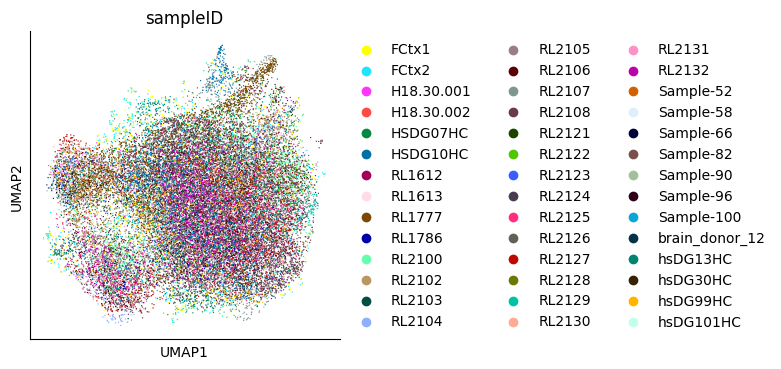

In [18]:
sc.pl.umap(astro_use, color = "sampleID")

In [19]:
astro_use.write_h5ad('/data1/trajectory_JL/step_2_scvi_result_data/astro_scvi_240308.h5ad')

# Palantir

In [ ]:
# astro_use = sc.read_h5ad('/data1/trajectory_JL/step_2_scvi_result_data/astro_scvi_240308.h5ad')

/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categoric

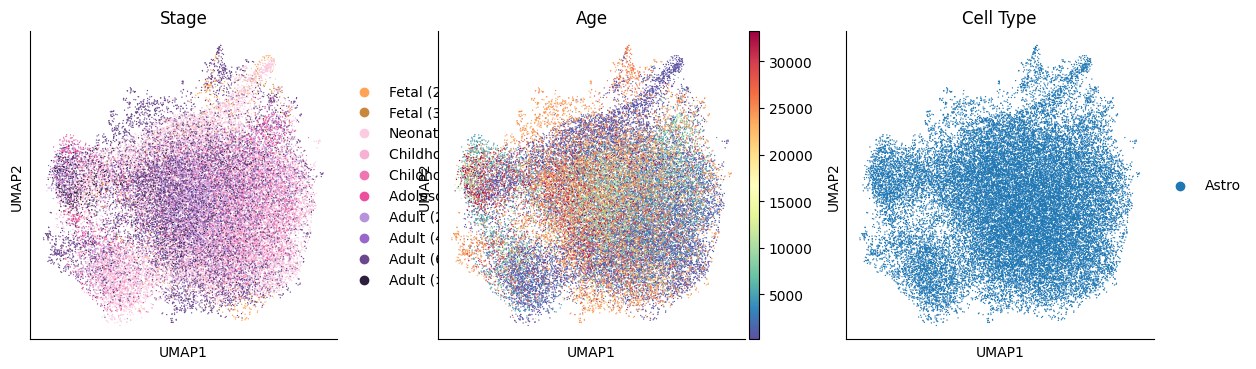

In [20]:
sc.pl.umap(astro_use, color = ["Stage", "Age", "Cell Type"])

## 1. diffusion components, impute X

In [5]:
dm_res = palantir.utils.run_diffusion_maps(astro_use, pca_key = "X_scVI_sampleID")
ms_data = palantir.utils.determine_multiscale_space(astro_use)

In [6]:
imputed_X = palantir.utils.run_magic_imputation(astro_use)

/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9

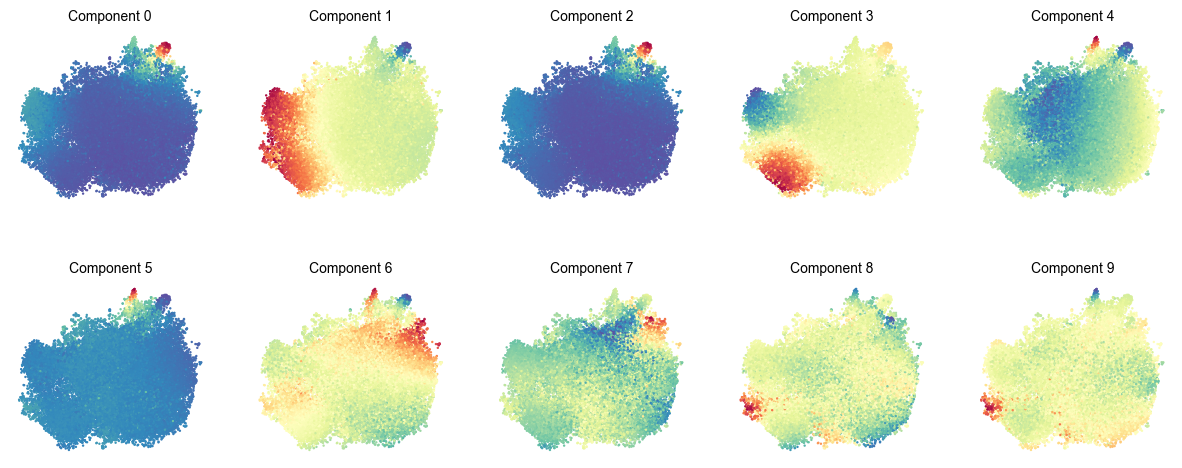

In [7]:
palantir.plot.plot_diffusion_components(astro_use)
plt.show()

## 2. run pseudotime

In [ ]:
start_cell = astro_use.obs[astro_use.obs["Age"] == 154].index[0]
# astro_use.obs["Age"].min()

RL2103_AAACCCACAGAACATA-1


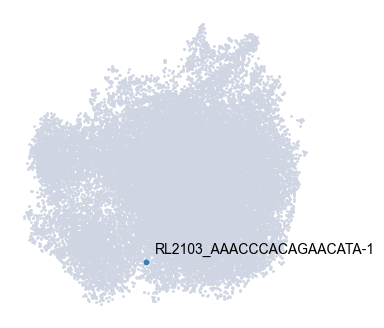

In [ ]:
# RL2103_AAACCCACAGAACATA-1
print(start_cell)
start_cell_spot = pd.Series(
    [start_cell],
    index=[start_cell],
)
palantir.plot.highlight_cells_on_umap(astro_use, start_cell_spot)
plt.show()

2-2 run pseudotime and save

In [ ]:
pr_res = palantir.core.run_palantir(
    astro_use, start_cell)

Sampling and flocking waypoints...
Time for determining waypoints: 0.2234466592470805 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...


/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/home/sonic/miniconda3/envs/BrainTumor/lib/python3.9

Time for shortest paths: 1.770218026638031 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 0.9996
Correlation at iteration 2: 1.0000
Entropy and branch probabilities...
Markov chain construction...
Identification of terminal states...
Computing fundamental matrix and absorption probabilities...
Project results to all cells...


In [ ]:
astro_use.write_h5ad('/data1/trajectory_JL/step_3_pseudotime_result_data/astro_pseudotime_240320.h5ad')

2-3 Name each lineages

In [19]:
astro_use.obsm['branch_masks'] = astro_use.obsm['branch_masks'].rename(columns = {'RL1777_CCCGAAGCATGGAGAC-1': 'Lineage_1',
                                                   'RL2127_GAATCACAGTGTTGAA-1': 'Lineage_2',
                                                   'RL2127_TAACTTCCACGGTAGA-1': 'Lineage_3'}).copy()

astro_use.obsm['palantir_fate_probabilities'] = astro_use.obsm['palantir_fate_probabilities'].rename(columns = {'RL1777_CCCGAAGCATGGAGAC-1': 'Lineage_1',
                                                   'RL2127_GAATCACAGTGTTGAA-1': 'Lineage_2',
                                                   'RL2127_TAACTTCCACGGTAGA-1': 'Lineage_3'}).copy()

## 3. Data for plotting

In [16]:
astro_use.layers['MAGIC_imputed_data'] = imputed_X

In [20]:
gene_trends = palantir.presults.compute_gene_trends(
    astro_use,
    expression_key="MAGIC_imputed_data",
)

Lineage_1
[2024-03-20 10:52:55,155] [INFO    ] Using sparse Gaussian Process since n_landmarks (500) < n_samples (7,234) and rank = 1.0.
[2024-03-20 10:52:55,157] [INFO    ] Using covariance function Matern52(ls=1.0).
Lineage_2
[2024-03-20 10:52:59,025] [INFO    ] Using sparse Gaussian Process since n_landmarks (500) < n_samples (4,847) and rank = 1.0.
[2024-03-20 10:52:59,027] [INFO    ] Using covariance function Matern52(ls=1.0).
Lineage_3
[2024-03-20 10:53:03,647] [INFO    ] Using sparse Gaussian Process since n_landmarks (500) < n_samples (8,632) and rank = 1.0.
[2024-03-20 10:53:03,648] [INFO    ] Using covariance function Matern52(ls=1.0).
